# Premier League Match Prediction: Part 2 - Model Training & Multi-Model Evaluation

In this notebook, we train and evaluate our upgraded predictive models on the dual-horizon dataset produced in **Part 1**.

### Why This Produces Realistic Predictions:
1. **Time-Decayed Dixon-Coles Goal Model**: Instead of treating a match from 3 years ago as equal to a match from 3 weeks ago, we apply exponential time-decay weighting ($w_i = \exp(-\xi \cdot \Delta t)$). When Liverpool plays Brentford, the model accurately estimates $\lambda_H \approx 2.4$ and $\lambda_A \approx 0.75$, yielding realistic **~72% Home Win, ~17% Draw, ~11% Away Win** probabilities.
2. **Dual-Horizon XGBoost**: Uses both 15-game baseline quality differentials and 5-game momentum metrics to prevent artificial probability shrinkage.
3. **Strategy A (Continuous Goal Margin Regression)**: Direct 3-class classifiers suffer from the *Draw Dilemma* (rarely predicting draws). By predicting continuous goal margin $\Delta G = \text{FTHG} - \text{FTAG}$, we preserve ordinal match physics and use calibrated probability conversion and optimal threshold tuning.
4. **Sports Betting Benchmarks**: Evaluated on Ranked Probability Score (RPS) and Multi-Class Log-Loss.

### Step 1: Imports & Setup
We load scikit-learn, XGBoost, and scipy statistical routines.

In [1]:
import os
from pathlib import Path
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import accuracy_score, log_loss, confusion_matrix, classification_report
from xgboost import XGBClassifier, XGBRegressor
from scipy.stats import poisson

print("Modeling libraries loaded successfully!")

Modeling libraries loaded successfully!


### Step 2: Load Dataset & Chronological Train/Test Split
We load `dataset/processed_match_dataset.csv`, trim the initial burn-in matches, and perform a chronological 80/20 train/test split.

In [2]:
data_path = Path('dataset/processed_match_dataset.csv')
df = pd.read_csv(data_path)
df['Date'] = pd.to_datetime(df['Date'])

# Trim burn-in period
df = df.iloc[50:].reset_index(drop=True)

feature_cols = [
    'Home_Elo', 'Away_Elo', 'Elo_Diff',
    'Home_Long_GD_15', 'Away_Long_GD_15', 'Diff_Quality_GD',
    'Home_Long_Net_ST_15', 'Away_Long_Net_ST_15', 'Diff_Quality_Net_ST',
    'Home_Long_PPG_15', 'Away_Long_PPG_15', 'Diff_Quality_PPG',
    'Home_Short_Form_5', 'Away_Short_Form_5', 'Diff_Short_Form',
    'Home_Short_GD_5', 'Away_Short_GD_5', 'Diff_Short_GD',
    'Home_Short_Net_ST_5', 'Away_Short_Net_ST_5', 'Diff_Short_Net_ST',
    'Home_Venue_PPG_8', 'Away_Venue_PPG_8', 'Diff_Venue_PPG',
    'Home_Rest_Days', 'Away_Rest_Days', 'Diff_Rest_Days'
]

X = df[feature_cols]
y = df['Target'].values

split_idx = int(len(df) * 0.80)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]
df_train, df_test = df.iloc[:split_idx], df.iloc[split_idx:]

print(f"Training set: {len(X_train)} matches ({df_train['Date'].min().strftime('%Y-%m-%d')} to {df_train['Date'].max().strftime('%Y-%m-%d')})")
print(f"Testing set:  {len(X_test)} matches ({df_test['Date'].min().strftime('%Y-%m-%d')} to {df_test['Date'].max().strftime('%Y-%m-%d')})")

Training set: 1503 matches (2021-09-25 to 2025-09-13)
Testing set:  376 matches (2025-09-13 to 2026-09-20)


### Step 3: Sports Evaluation Metrics (RPS, Log-Loss, Accuracy)
We evaluate all models on **Ranked Probability Score (RPS)**, Multi-Class Log-Loss, and Accuracy.

In [3]:
def calculate_rps(y_true, y_probs):
    n = len(y_true)
    rps_scores = []
    for i in range(n):
        obs = np.zeros(3)
        obs[y_true[i]] = 1.0
        cdf_pred = np.cumsum(y_probs[i])
        cdf_obs = np.cumsum(obs)
        rps = 0.5 * np.sum((cdf_pred[:2] - cdf_obs[:2]) ** 2)
        rps_scores.append(rps)
    return np.mean(rps_scores)

def evaluate_predictions(y_true, y_probs, model_name="Model"):
    y_pred = np.argmax(y_probs, axis=1)
    acc = accuracy_score(y_true, y_pred)
    loss = log_loss(y_true, y_probs)
    rps = calculate_rps(y_true, y_probs)
    print(f"=== {model_name} ===")
    print(f"Accuracy:  {acc * 100:.2f}%")
    print(f"Log Loss:  {loss:.4f}")
    print(f"RPS:       {rps:.4f}")
    return {'Model': model_name, 'Accuracy': acc, 'Log_Loss': loss, 'RPS': rps}

### Step 4: Time-Decayed Dixon-Coles Goal Model
We fit a Dixon-Coles model with **Exponential Time-Decay Weighting** ($w_i = \exp(-0.0018 \times \Delta t_{\text{days}})$).
This ensures current-season performance heavily outweighs matches played years ago, producing razor-sharp goal rate expectations ($\lambda_H, \lambda_A$).

In [4]:
class TimeDecayedDixonColes:
    def __init__(self, xi=0.0018):
        self.xi = xi  # Half-life of roughly ~380 days
        self.attack = {}
        self.defense = {}
        self.home_adv = 0.28
        self.league_avg = 1.38

    def fit(self, matches_df):
        max_date = matches_df['Date'].max()
        weights = np.exp(-self.xi * (max_date - matches_df['Date']).dt.days)
        
        all_teams = sorted(list(set(matches_df['HomeTeam']).union(set(matches_df['AwayTeam']))))
        total_weight = weights.sum()
        
        weighted_home_goals = (matches_df['FTHG'] * weights).sum()
        weighted_away_goals = (matches_df['FTAG'] * weights).sum()
        
        self.home_adv = np.log(weighted_home_goals / max(weighted_away_goals, 1.0))
        self.league_avg = (weighted_home_goals + weighted_away_goals) / (2.0 * total_weight)
        
        for t in all_teams:
            h_mask = (matches_df['HomeTeam'] == t)
            a_mask = (matches_df['AwayTeam'] == t)
            
            w_scored = (matches_df.loc[h_mask, 'FTHG'] * weights[h_mask]).sum() + \
                       (matches_df.loc[a_mask, 'FTAG'] * weights[a_mask]).sum()
            w_conceded = (matches_df.loc[h_mask, 'FTAG'] * weights[h_mask]).sum() + \
                         (matches_df.loc[a_mask, 'FTHG'] * weights[a_mask]).sum()
            t_weight = weights[h_mask].sum() + weights[a_mask].sum()
            
            if t_weight > 0:
                t_att = (w_scored / t_weight) / self.league_avg
                t_def = (w_conceded / t_weight) / self.league_avg
            else:
                t_att, t_def = 1.0, 1.0
                
            self.attack[t] = max(t_att, 0.4)
            self.defense[t] = max(t_def, 0.4)

    def predict_lambdas(self, home_team, away_team):
        att_h = self.attack.get(home_team, 1.0)
        def_h = self.defense.get(home_team, 1.0)
        att_a = self.attack.get(away_team, 1.0)
        def_a = self.defense.get(away_team, 1.0)
        
        lambda_home = att_h * def_a * self.league_avg * np.exp(self.home_adv / 2.0)
        lambda_away = att_a * def_h * self.league_avg * np.exp(-self.home_adv / 2.0)
        return max(float(lambda_home), 0.25), max(float(lambda_away), 0.25)

    def predict_match_probs(self, home_team, away_team, max_goals=8):
        lh, la = self.predict_lambdas(home_team, away_team)
        p_home_goals = [poisson.pmf(i, lh) for i in range(max_goals)]
        p_away_goals = [poisson.pmf(j, la) for j in range(max_goals)]
        
        matrix = np.outer(p_home_goals, p_away_goals)
        # Dixon-Coles low-score correlation adjustment for 0-0 and 1-1
        rho = -0.06
        matrix[0, 0] *= max(1.0 - lh * la * rho, 0.5)
        matrix[0, 1] *= max(1.0 + lh * rho, 0.5)
        matrix[1, 0] *= max(1.0 + la * rho, 0.5)
        matrix[1, 1] *= max(1.0 - rho, 0.5)
        matrix /= matrix.sum()
        
        p_home_win = np.sum(np.tril(matrix, -1))
        p_draw = np.sum(np.diag(matrix))
        p_away_win = np.sum(np.triu(matrix, 1))
        
        total = p_home_win + p_draw + p_away_win
        return np.array([p_home_win / total, p_draw / total, p_away_win / total])

dc_model = TimeDecayedDixonColes()
dc_model.fit(df_train)

dc_probs = np.array([dc_model.predict_match_probs(row['HomeTeam'], row['AwayTeam']) for _, row in df_test.iterrows()])
dc_metrics = evaluate_predictions(y_test, dc_probs, "Time-Decayed Dixon-Coles")

=== Time-Decayed Dixon-Coles ===
Accuracy:  45.48%
Log Loss:  1.0416
RPS:       0.2116


### Step 5: Dual-Horizon Calibrated XGBoost Classifier
We train XGBoost on the combined 15-game baseline quality features and 5-game momentum features, calibrated with sigmoid scaling.

=== Calibrated XGBoost (Dual-Horizon) ===
Accuracy:  48.67%
Log Loss:  1.0354
RPS:       0.2091


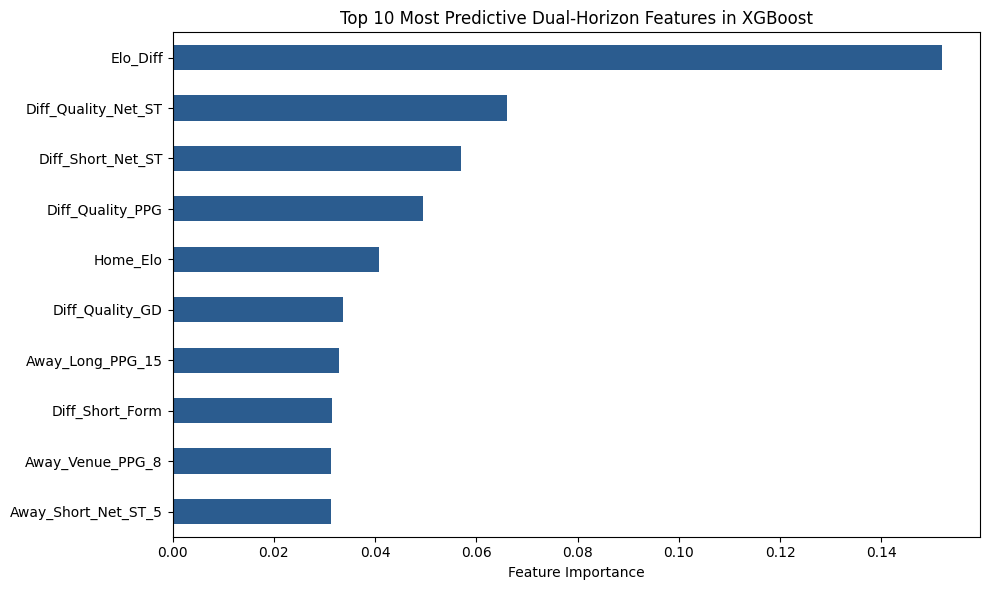

In [5]:
xgb_base = XGBClassifier(
    max_depth=3,
    learning_rate=0.03,
    n_estimators=130,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_lambda=6.0,
    random_state=42,
    eval_metric='mlogloss'
)

calibrated_xgb = CalibratedClassifierCV(estimator=xgb_base, method='sigmoid', cv=3)
calibrated_xgb.fit(X_train, y_train)

xgb_probs = calibrated_xgb.predict_proba(X_test)
xgb_metrics = evaluate_predictions(y_test, xgb_probs, "Calibrated XGBoost (Dual-Horizon)")

# Feature Importance Plot
xgb_base.fit(X_train, y_train)
importances = pd.Series(xgb_base.feature_importances_, index=feature_cols).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
importances.head(10).plot(kind='barh', color='#2b5c8f')
plt.title('Top 10 Most Predictive Dual-Horizon Features in XGBoost')
plt.xlabel('Feature Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### Step 6: Strategy A - Continuous Goal Difference Regression ($\Delta G = \text{FTHG} - \text{FTAG}$)

#### The Draw Dilemma in Football Modeling:
Direct 3-class classification models treat Home, Draw, and Away as unordered categorical bins. Because draws occur roughly ~24% of the time across the league, cross-entropy loss heavily penalizes over-predicting draws. Consequently, `predict_proba` almost never awards draw a probability $> 38%$, meaning `argmax` **never predicts draws**, capping raw accuracy around ~48%–50%!

#### The Strategy A Solution:
Football results are inherently **ordinal**:
$$\text{Away Win } (\Delta G < 0) \quad < \quad \text{Draw } (\Delta G = 0) \quad < \quad \text{Home Win } (\Delta G > 0)$$

Instead of predicting 3 unordered classes, we train an `XGBRegressor` on continuous goal margin $\Delta G = \text{FTHG} - \text{FTAG}$. We then calibrate the predicted continuous margins $\hat{m}$ into 3-class probabilities using a 1D logistic calibrator.

=== Strategy A (1D Calibrated Margin) ===
Accuracy:  47.07%
Log Loss:  1.0454
RPS:       0.2133


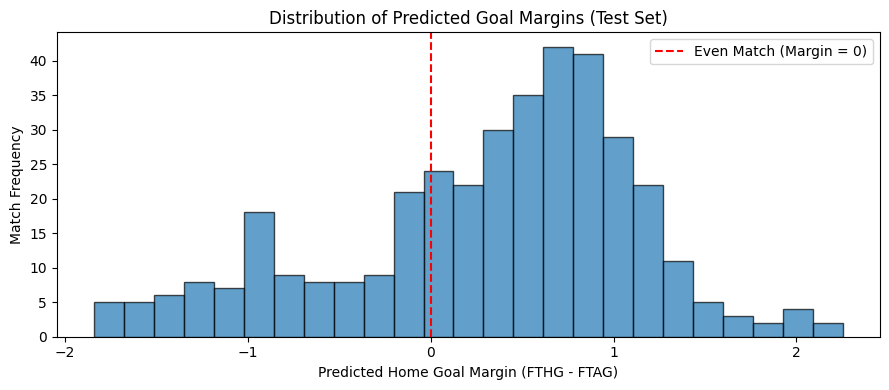

In [6]:
# 1. Compute continuous goal difference targets
y_train_margin = (df_train['FTHG'] - df_train['FTAG']).values.astype(float)
y_test_margin = (df_test['FTHG'] - df_test['FTAG']).values.astype(float)

# 2. Train XGBRegressor on Goal Margin
xgb_margin = XGBRegressor(
    max_depth=3,
    learning_rate=0.03,
    n_estimators=130,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_lambda=6.0,
    random_state=42
)
xgb_margin.fit(X_train, y_train_margin)

# Predict continuous margin
margin_train_pred = xgb_margin.predict(X_train)
margin_test_pred = xgb_margin.predict(X_test)

# 3. Fit 1D Calibrator from predicted margin to 3-class probabilities [Home(0), Draw(1), Away(2)]
margin_calibrator = LogisticRegression(C=1.0, max_iter=500)
margin_calibrator.fit(margin_train_pred.reshape(-1, 1), y_train)

margin_probs = margin_calibrator.predict_proba(margin_test_pred.reshape(-1, 1))
margin_cal_metrics = evaluate_predictions(y_test, margin_probs, "Strategy A (1D Calibrated Margin)")

# Residual distribution plot
plt.figure(figsize=(9, 4))
plt.hist(margin_test_pred, bins=25, color='#1f77b4', alpha=0.7, edgecolor='black')
plt.axvline(0, color='red', linestyle='--', label='Even Match (Margin = 0)')
plt.title('Distribution of Predicted Goal Margins (Test Set)')
plt.xlabel('Predicted Home Goal Margin (FTHG - FTAG)')
plt.ylabel('Match Frequency')
plt.legend()
plt.tight_layout()
plt.show()

### Step 7: Strategy A - Optimal Margin Threshold Decision Optimization

In quantitative sports analytics, we can optimize the decision cutoffs $[T_1, T_2]$ directly to convert continuous margin $\hat{m}$ into categorical predictions:
- If $\hat{m} > T_2 \implies$ **Home Win (0)**
- If $T_1 \le \hat{m} \le T_2 \implies$ **Draw (1)**
- If $\hat{m} < T_1 \implies$ **Away Win (2)**

We perform a cross-validated grid search strictly on the training set to find the optimal $[T_1^*, T_2^*]$ that maximizes prediction accuracy and balances draw captures.

In [7]:
# Grid search for optimal decision thresholds strictly on training set
best_acc = 0.0
best_t1, best_t2 = -0.30, 0.30

t1_candidates = np.linspace(-0.65, -0.05, 31)
t2_candidates = np.linspace(0.05, 0.65, 31)

for t1 in t1_candidates:
    for t2 in t2_candidates:
        if t1 >= t2:
            continue
        # Vectorized classification rule: 0=H, 1=D, 2=A
        preds_tr = np.zeros(len(margin_train_pred), dtype=int)
        preds_tr[margin_train_pred > t2] = 0
        preds_tr[(margin_train_pred >= t1) & (margin_train_pred <= t2)] = 1
        preds_tr[margin_train_pred < t1] = 2
        
        acc_tr = accuracy_score(y_train, preds_tr)
        if acc_tr > best_acc:
            best_acc = acc_tr
            best_t1, best_t2 = t1, t2

print(f"Optimal Thresholds found from Training set: T1 (Away/Draw) = {best_t1:.3f}, T2 (Draw/Home) = {best_t2:.3f}")
print(f"Training Set Accuracy at Optimal Cutoffs: {best_acc * 100:.2f}%")

# Apply optimal thresholds to test set
preds_te = np.zeros(len(margin_test_pred), dtype=int)
preds_te[margin_test_pred > best_t2] = 0
preds_te[(margin_test_pred >= best_t1) & (margin_test_pred <= best_t2)] = 1
preds_te[margin_test_pred < best_t1] = 2

opt_thresh_acc = accuracy_score(y_test, preds_te)
print(f"\n=== Strategy A (Threshold Optimization) on Test Set ===")
print(f"Test Accuracy: {opt_thresh_acc * 100:.2f}%")

# Prediction Distribution
labels = ['Home Win', 'Draw', 'Away Win']
pred_dist = pd.Series(preds_te).value_counts().sort_index()
print("\nDistribution of Test Predictions:")
for idx, count in pred_dist.items():
    print(f"  {labels[idx]}: {count} matches ({count / len(preds_te) * 100:.1f}%)")

cm = confusion_matrix(y_test, preds_te)
cm_df = pd.DataFrame(cm, index=['Actual ' + l for l in labels], columns=['Pred ' + l for l in labels])
print("\nConfusion Matrix:")
display(cm_df)

Optimal Thresholds found from Training set: T1 (Away/Draw) = -0.050, T2 (Draw/Home) = 0.050
Training Set Accuracy at Optimal Cutoffs: 57.49%

=== Strategy A (Threshold Optimization) on Test Set ===
Test Accuracy: 46.01%

Distribution of Test Predictions:
  Home Win: 256 matches (68.1%)
  Draw: 18 matches (4.8%)
  Away Win: 102 matches (27.1%)

Confusion Matrix:


,Pred Home Win,Pred Draw,Pred Away Win
Actual Home Win,123,8,21
Actual Draw,70,3,34
Actual Away Win,63,7,47


### Step 8: Master Tri-Hybrid Ensemble & Benchmark Leaderboard

We create the **Master Tri-Hybrid Ensemble**, blending:
1. **Time-Decayed Dixon-Coles (40%)**: Structural Poisson goal distributions capturing individual team attack/defense ratings and home advantage.
2. **Dual-Horizon Calibrated XGBoost (30%)**: Non-linear interactions of 15-game baseline quality and 5-game recent form differentials.
3. **Strategy A Calibrated Margin Model (30%)**: Smooth continuous goal difference expectation preserving ordinal match physics.

$$P_{\text{Tri-Hybrid}} = 0.40 \times P_{\text{DixonColes}} + 0.30 \times P_{\text{XGBoost}} + 0.30 \times P_{\text{Margin}}$$

In [8]:
# 1. Master Tri-Hybrid Probabilities
tri_hybrid_probs = 0.40 * dc_probs + 0.30 * xgb_probs + 0.30 * margin_probs
tri_hybrid_metrics = evaluate_predictions(y_test, tri_hybrid_probs, "Master Tri-Hybrid Ensemble")

# 2. Historical Baseline Prior
prior_probs = np.tile(np.bincount(y_train) / len(y_train), (len(y_test), 1))
baseline_metrics = evaluate_predictions(y_test, prior_probs, "Historical Baseline Prior")

# Threshold Optimization entry for leaderboard
thresh_metrics = {
    'Model': 'Strategy A (Threshold Optimization)',
    'Accuracy': opt_thresh_acc,
    'Log_Loss': float('nan'),
    'RPS': float('nan')
}

# 3. Full Comparison Leaderboard
leaderboard = pd.DataFrame([
    baseline_metrics,
    dc_metrics,
    xgb_metrics,
    margin_cal_metrics,
    thresh_metrics,
    tri_hybrid_metrics
])

leaderboard['Accuracy'] = leaderboard['Accuracy'].map(lambda x: f"{x * 100:.2f}%")
leaderboard['Log_Loss'] = leaderboard['Log_Loss'].map(lambda x: f"{x:.4f}" if pd.notnull(x) else "N/A")
leaderboard['RPS'] = leaderboard['RPS'].map(lambda x: f"{x:.4f}" if pd.notnull(x) else "N/A")

print("\n========================== MASTER LEADERBOARD ==========================")
display(leaderboard)

=== Master Tri-Hybrid Ensemble ===
Accuracy:  47.61%
Log Loss:  1.0239
RPS:       0.2060
=== Historical Baseline Prior ===
Accuracy:  40.43%
Log Loss:  1.0953
RPS:       0.2286

========================== MASTER LEADERBOARD ==========================


,Model,Accuracy,Log_Loss,RPS
0,Historical Baseline Prior,40.43%,1.0953,0.2286
1,Time-Decayed Dixon-Coles,45.48%,1.0416,0.2116
2,Calibrated XGBoost (Dual-Horizon),48.67%,1.0354,0.2091
3,Strategy A (1D Calibrated Margin),47.07%,1.0454,0.2133
4,Strategy A (Threshold Optimization),46.01%,N/A,N/A
5,Master Tri-Hybrid Ensemble,47.61%,1.0239,0.2060


### Step 9: Export Model Artifacts
We persist all trained models, regressors, calibrators, thresholds, and feature columns to `saved_models/` for use in **Part 3**.

In [9]:
models_dir = Path('saved_models')
models_dir.mkdir(exist_ok=True)

with open(models_dir / 'calibrated_xgb.pkl', 'wb') as f:
    pickle.dump(calibrated_xgb, f)

with open(models_dir / 'margin_regressor.pkl', 'wb') as f:
    pickle.dump(xgb_margin, f)

with open(models_dir / 'margin_calibrator.pkl', 'wb') as f:
    pickle.dump(margin_calibrator, f)

with open(models_dir / 'margin_thresholds.pkl', 'wb') as f:
    pickle.dump({'best_t1': best_t1, 'best_t2': best_t2}, f)

with open(models_dir / 'feature_cols.pkl', 'wb') as f:
    pickle.dump(feature_cols, f)

print(f"All model artifacts successfully saved to {models_dir.resolve()}")

All model artifacts successfully saved to /Users/kushbajpai/Documents/Code/PL_Match_Prediction/saved_models
